In [3]:
import json
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

SEED = 42

with open("../dados/metadados.json", encoding="utf-8") as f:
    meta = json.load(f)

df = pd.read_csv("../dados/dataset_fiscal.csv")
colunas = meta["colunas_informativas"] + meta["colunas_ruido"]
alvo = meta["alvo"]

X = df[colunas]
y = df[alvo]
print("Dimensões:", df.shape)
print("Proporção das classes:")
print(y.value_counts(normalize=True).round(3))

Dimensões: (10000, 11)
Proporção das classes:
risco_fiscal
0    0.846
1    0.154
Name: proportion, dtype: float64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Treino: {X_train.shape[0]} instâncias | Teste: {X_test.shape[0]} instâncias")
print("Classe 1 no treino:", round(y_train.mean(), 3), "| no teste:", round(y_test.mean(), 3))

# Salva as partições para que os notebooks seguintes usem exatamente os mesmos dados
X_train.assign(**{alvo: y_train}).to_csv("../dados/treino.csv", index=False)
X_test.assign(**{alvo: y_test}).to_csv("../dados/teste.csv", index=False)

Treino: 8000 instâncias | Teste: 2000 instâncias
Classe 1 no treino: 0.154 | no teste: 0.154


In [5]:
peso_classe_1 = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (razão Classe 0 / Classe 1): {peso_classe_1:.2f}")

modelo_rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=SEED,
)

modelo_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=peso_classe_1,
    eval_metric="aucpr",
    n_jobs=-1,
    random_state=SEED,
)

modelo_rf.fit(X_train, y_train)
modelo_xgb.fit(X_train, y_train)
print("Modelos treinados.")

scale_pos_weight (razão Classe 0 / Classe 1): 5.49
Modelos treinados.


In [6]:
def avaliar(nome, modelo):
    prob = modelo.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    return {
        "Modelo": nome,
        "Acurácia": accuracy_score(y_test, pred),
        "Precisão": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "PR-AUC": average_precision_score(y_test, prob),
        "ROC-AUC": roc_auc_score(y_test, prob),
    }


tabela = pd.DataFrame(
    [avaliar("Random Forest", modelo_rf), avaliar("XGBoost", modelo_xgb)]
).set_index("Modelo")

print(tabela.round(4))

# Referências para interpretar as métricas
acuracia_ingenua = 1 - y_test.mean()
print(f"\nAcurácia de um classificador ingênuo (sempre Classe 0): {acuracia_ingenua:.4f}")
print(f"PR-AUC de um classificador aleatório (= prevalência da Classe 1): {y_test.mean():.4f}")

os.makedirs("../resultados", exist_ok=True)
tabela.round(4).to_csv("../resultados/metricas_modelos.csv")

               Acurácia  Precisão  Recall  F1-Score  PR-AUC  ROC-AUC
Modelo                                                              
Random Forest    0.9325    0.9220  0.6136    0.7368  0.8772   0.9595
XGBoost          0.9370    0.7935  0.7987    0.7961  0.8845   0.9628

Acurácia de um classificador ingênuo (sempre Classe 0): 0.8460
PR-AUC de um classificador aleatório (= prevalência da Classe 1): 0.1540


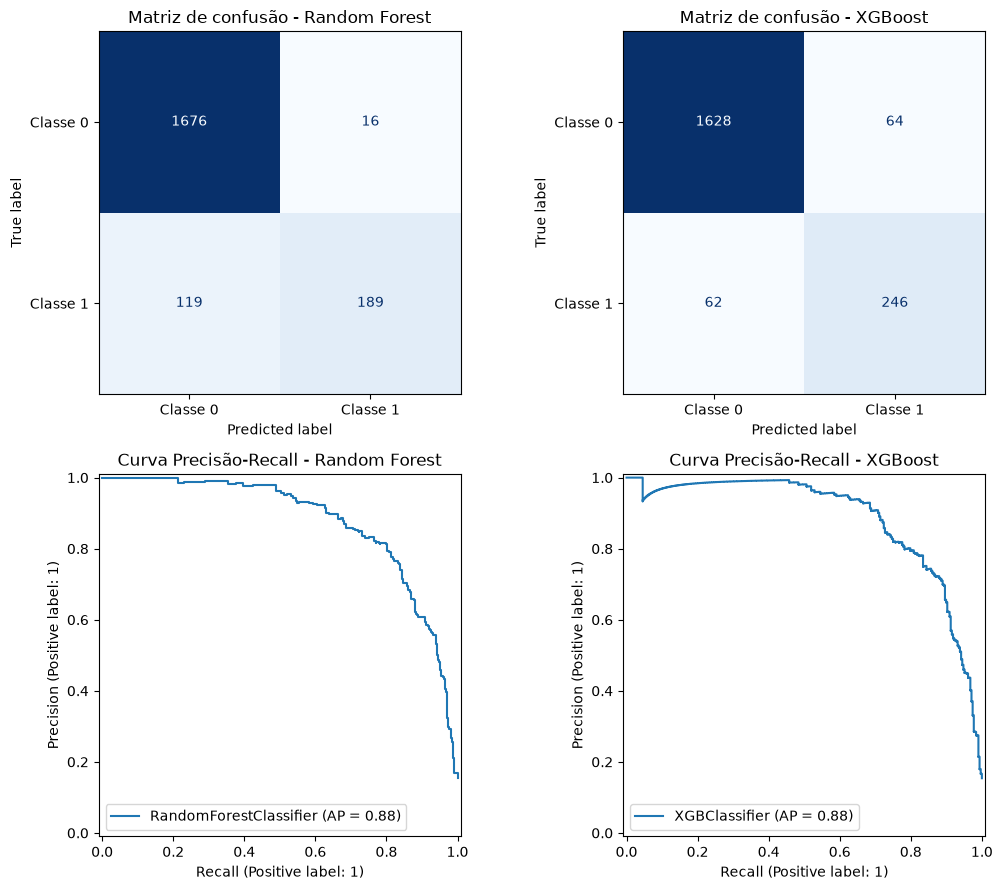

In [7]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 9))

for i, (nome, modelo) in enumerate(
    [("Random Forest", modelo_rf), ("XGBoost", modelo_xgb)]
):
    prob = modelo.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Classe 0", "Classe 1"]).plot(
        ax=eixos[0, i], cmap="Blues", colorbar=False
    )
    eixos[0, i].set_title(f"Matriz de confusão - {nome}")

    PrecisionRecallDisplay.from_estimator(modelo, X_test, y_test, ax=eixos[1, i])
    eixos[1, i].set_title(f"Curva Precisão-Recall - {nome}")

plt.tight_layout()
plt.savefig("../resultados/avaliacao_modelos.png", dpi=300)
plt.show()

In [8]:
os.makedirs("../resultados/modelos", exist_ok=True)
joblib.dump(modelo_rf, "../resultados/modelos/random_forest.joblib")
joblib.dump(modelo_xgb, "../resultados/modelos/xgboost.joblib")
print("Modelos salvos em resultados/modelos/")

Modelos salvos em resultados/modelos/
